# Actividad 5 — Preparación de datos, entrenamiento y registro con MLflow
**Gestión de proyectos de inteligencia artificial · Universidad Tecmilenio**

**Problema:** regresión del costo anual del seguro médico (`charges`, USD) a partir de edad, sexo, IMC, número de hijos, tabaquismo y región.

**Flujo del cuaderno**
1. Preparación del entorno (local o Google Colab)
2. Calidad de los datos originales
3. Limpieza, estandarización y versionamiento (`fuentes/datos_prep.py`)
4. Análisis exploratorio: patrones y anomalías (`fuentes/eda.py`)
5. Entrenamiento con Grid Search + validación cruzada y registro en MLflow (`fuentes/train.py`)
6. Comparación de modelos y pruebas estadísticas
7. Evidencia de MLflow: corridas, parámetros, métricas y Model Registry
8. Conclusiones

## 1. Preparación del entorno
En Colab, la celda clona el repositorio e instala dependencias; en local solo se posiciona en la raíz del repositorio.

In [1]:
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/lTOPlZeuS/Actividad5.git"

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    if not Path("Actividad5").exists():
        subprocess.run(["git", "clone", REPO_URL, "Actividad5"], check=True)
    os.chdir("Actividad5")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:
    raiz = Path.cwd()
    while not (raiz / "requirements.txt").exists() and raiz != raiz.parent:
        raiz = raiz.parent
    os.chdir(raiz)

sys.path.insert(0, str(Path("fuentes").resolve()))
print("Directorio de trabajo:", Path.cwd())

Directorio de trabajo: /Users/jesus/Desktop/Actividad5


In [2]:
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
import datos_prep as dp

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 140)

## 2. Calidad de los datos originales
Fuente: *Medical Cost Personal Datasets* (Lantz, *Machine Learning with R*), 1 338 registros, 7 columnas.

In [3]:
ini = pd.read_csv("datos/datos_ini/insurance.csv")
print("Dimensiones:", ini.shape)
display(ini.head())
calidad = pd.DataFrame({
    "tipo": ini.dtypes.astype(str),
    "nulos": ini.isna().sum(),
    "valores_unicos": ini.nunique(),
})
display(calidad)
print("Duplicados exactos:", ini.duplicated().sum())
display(ini[ini.duplicated(keep=False)])
display(ini.describe().T)

Dimensiones: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.9000,0,yes,southwest,"16,884.9240"
1,18,male,33.7700,1,no,southeast,"1,725.5523"
2,28,male,33.0000,3,no,southeast,"4,449.4620"
3,33,male,22.7050,0,no,northwest,"21,984.4706"
4,32,male,28.8800,0,no,northwest,"3,866.8552"


,tipo,nulos,valores_unicos
age,int64,0,47
sex,str,0,2
bmi,float64,0,548
children,int64,0,6
smoker,str,0,2
region,str,0,4
charges,float64,0,1337


Duplicados exactos: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.5900,0,no,northwest,"1,639.5631"
581,19,male,30.5900,0,no,northwest,"1,639.5631"


,count,mean,std,min,25%,50%,75%,max
age,"1,338.0000",39.2070,14.0500,18.0000,27.0000,39.0000,51.0000,64.0000
bmi,"1,338.0000",30.6634,6.0982,15.9600,26.2963,30.4000,34.6938,53.1300
children,"1,338.0000",1.0949,1.2055,0.0000,0.0000,1.0000,2.0000,5.0000
charges,"1,338.0000","13,270.4223","12,110.0112","1,121.8739","4,740.2872","9,382.0330","16,639.9125","63,770.4280"


## 3. Limpieza, estandarización y versionamiento
`datos_prep.limpiar()` aplica, en orden: validación de esquema y tipos → estandarización de texto → manejo de nulos (mediana/moda; se descartan filas sin objetivo) → eliminación de duplicados → reglas de negocio (rangos y dominios) → detección de atípicos IQR (se marcan, no se eliminan) → variables derivadas (`obese`, `smoker_obese`).

La codificación One-Hot y el escalado se aplican **dentro del Pipeline** de cada modelo para evitar fuga de información entre pliegues.

In [4]:
subprocess.run([sys.executable, "fuentes/datos_prep.py"], check=True)
limp = pd.read_csv("datos/datos_limp/insurance_limpio.csv")
bitacora = json.loads(Path("datos/datos_limp/bitacora_limpieza.json").read_text())
print(f"Filas: {bitacora['filas_iniciales']} -> {bitacora['filas_finales']}")
print("Duplicados eliminados:", bitacora["duplicados"]["duplicados_eliminados"], "(índice", bitacora["duplicados"]["indices"], ")")
print("Filas eliminadas por reglas de negocio:", bitacora["reglas_negocio"]["filas_eliminadas"])
display(pd.DataFrame(bitacora["atipicos_iqr"]).T)
display(limp.head())

Filas: 1338 -> 1337
Duplicados eliminados: 1
Guardado en datos/datos_limp/insurance_limpio.csv | bitácora: datos/datos_limp/bitacora_limpieza.json
Filas: 1338 -> 1337
Duplicados eliminados: 1 (índice [581] )
Filas eliminadas por reglas de negocio: 0


,limite_inferior,limite_superior,n_atipicos,pct_atipicos,pct_fumadores_entre_atipicos
bmi,13.6750,47.3150,9.0000,0.6700,NaN
charges,"-13,120.7162","34,524.7776",139.0000,10.4000,97.8400


,age,sex,bmi,children,smoker,region,charges,obese,smoker_obese
0,19,female,27.9000,0,yes,southwest,"16,884.9240",0,0
1,18,male,33.7700,1,no,southeast,"1,725.5523",1,0
2,28,male,33.0000,3,no,southeast,"4,449.4620",1,0
3,33,male,22.7050,0,no,northwest,"21,984.4706",0,0
4,32,male,28.8800,0,no,northwest,"3,866.8552",0,0


### Prueba de robustez del limpiador
El dataset original es casi limpio, así que se inyectan errores sintéticos (nulos, mayúsculas/espacios, duplicados, valores fuera de dominio y de rango) para comprobar que cada regla actúa.

In [5]:
sucio = ini.head(8).copy()
sucio.loc[0, "sex"] = "  Female "
sucio.loc[1, "smoker"] = "YES"
sucio.loc[2, "bmi"] = np.nan
sucio.loc[3, "region"] = None
sucio.loc[4, "charges"] = np.nan          # sin objetivo -> se elimina
sucio.loc[5, "age"] = 130                 # fuera de rango -> se elimina
sucio.loc[6, "region"] = "centro"         # fuera de dominio -> se elimina
sucio = pd.concat([sucio, sucio.iloc[[7]]])  # duplicado
res, bit = dp.limpiar(sucio)
print(f"Filas {bit['filas_iniciales']} -> {bit['filas_finales']}")
print("Texto modificado:", bit["texto"]["valores_modificados"])
print("Imputaciones:", bit["nulos"]["imputaciones"])
print("Duplicados:", bit["duplicados"]["duplicados_eliminados"], "| Reglas:", {k: v for k, v in bit["reglas_negocio"].items() if v})
display(res)

Filas 9 -> 5
Texto modificado: {'sex': 1, 'smoker': 1, 'region': 0}
Imputaciones: {'bmi': {'n': 1, 'estrategia': 'mediana', 'valor': 27.74}, 'region': {'n': 1, 'estrategia': 'moda', 'valor': 'southeast'}}
Duplicados: 1 | Reglas: {'age_fuera_de_rango': 1, 'region_fuera_de_dominio': 1, 'filas_eliminadas': 2}


,age,sex,bmi,children,smoker,region,charges,obese,smoker_obese
0,19,female,27.9000,0,yes,southwest,"16,884.9240",0,0
1,18,male,33.7700,1,yes,southeast,"1,725.5523",1,1
2,28,male,27.7400,3,no,southeast,"4,449.4620",0,0
3,33,male,22.7050,0,no,southeast,"21,984.4706",0,0
4,37,female,27.7400,3,no,northwest,"7,281.5056",0,0


### Versionamiento del dataset
Cada versión queda identificada por su huella SHA-256 en `datos/MANIFEST.json`, por etiquetas Git (`datos-v1.0.0`, `datos-v1.1.0`) y por el registro del dataset (`mlflow.log_input`) en cada corrida.

In [6]:
manifest = json.loads(Path("datos/MANIFEST.json").read_text())
pd.DataFrame(manifest).T[["version", "archivo", "filas", "columnas", "sha256"]]

,version,archivo,filas,columnas,sha256
datos_ini,1.0.0,datos/datos_ini/insurance.csv,1338,7,505c1cbc2e63d0363bac59501563df2530aadf4cdb9cfe...
datos_limp,1.1.0,datos/datos_limp/insurance_limpio.csv,1337,9,456e2ef00e5ac3af65efde3744b0f3a5a9a5917a4bb655...


## 4. Análisis exploratorio: patrones y anomalías

**01_calidad_datos**

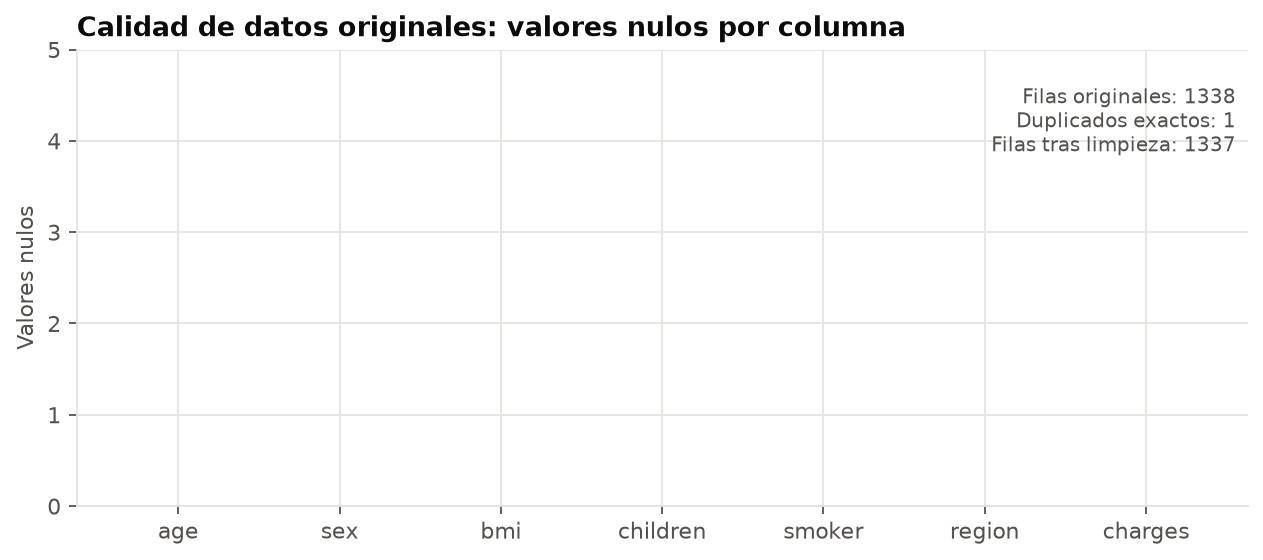

**02_distribucion_objetivo**

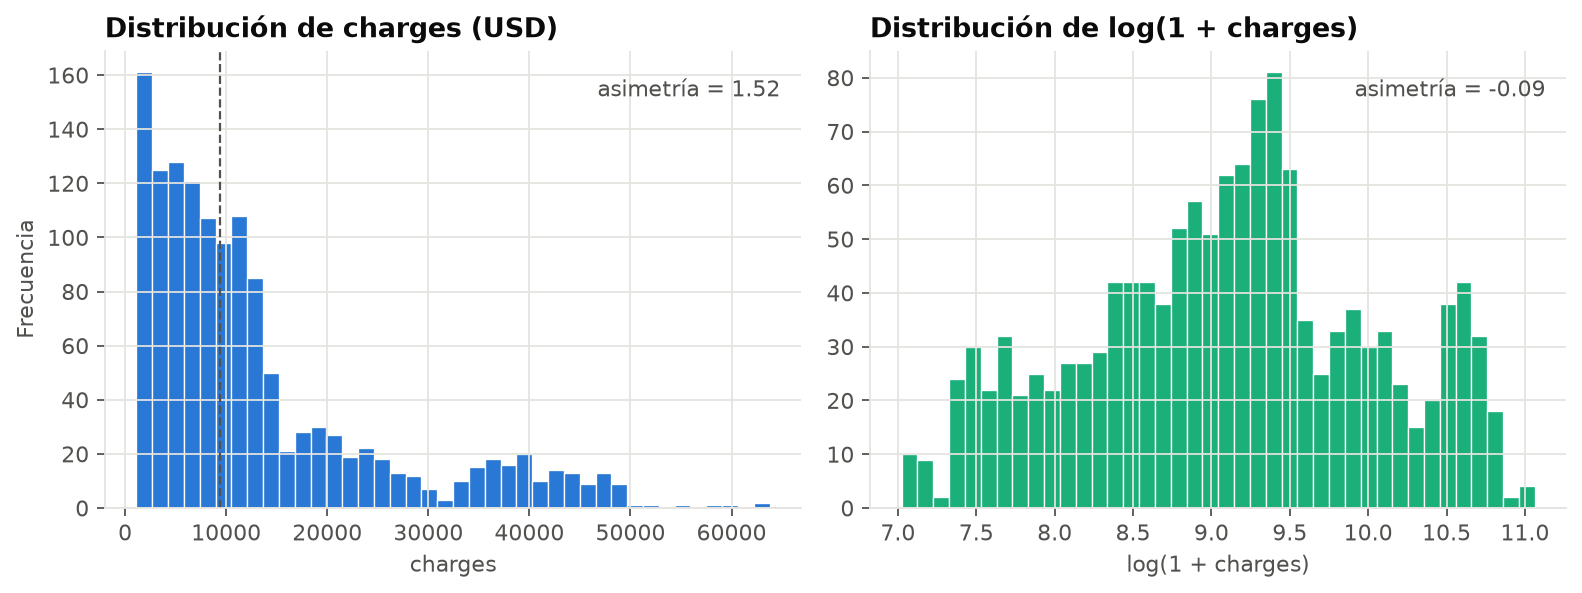

**03_charges_vs_edad**

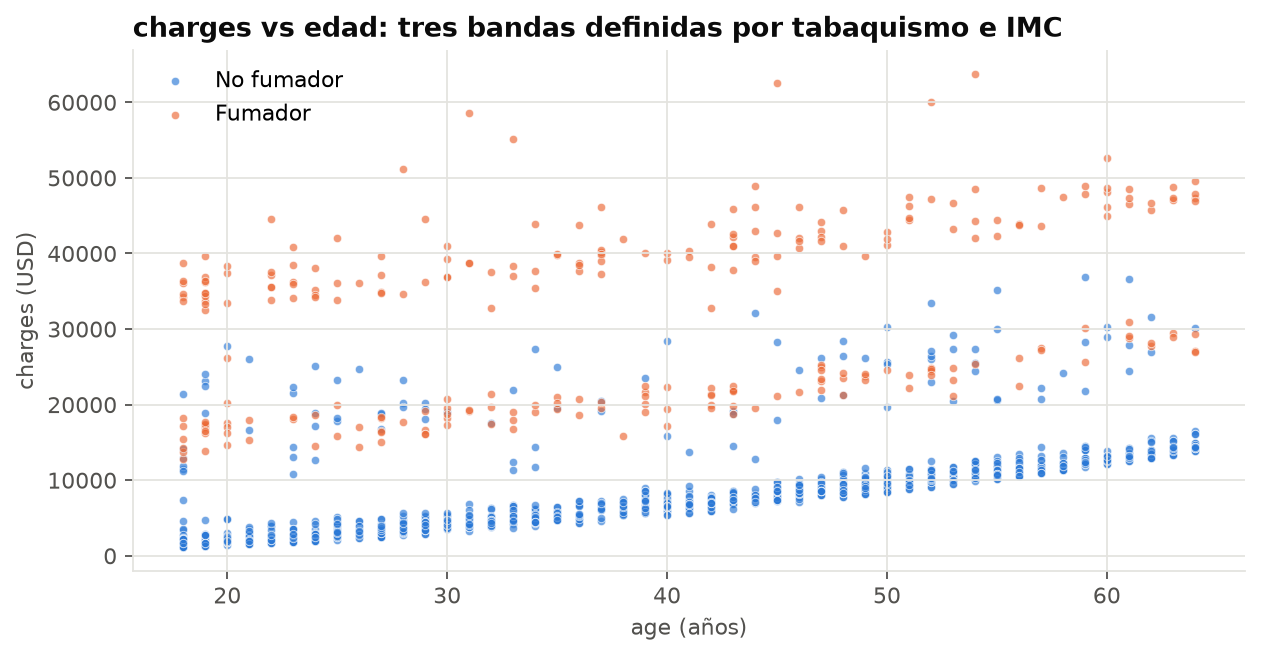

**04_charges_vs_imc**

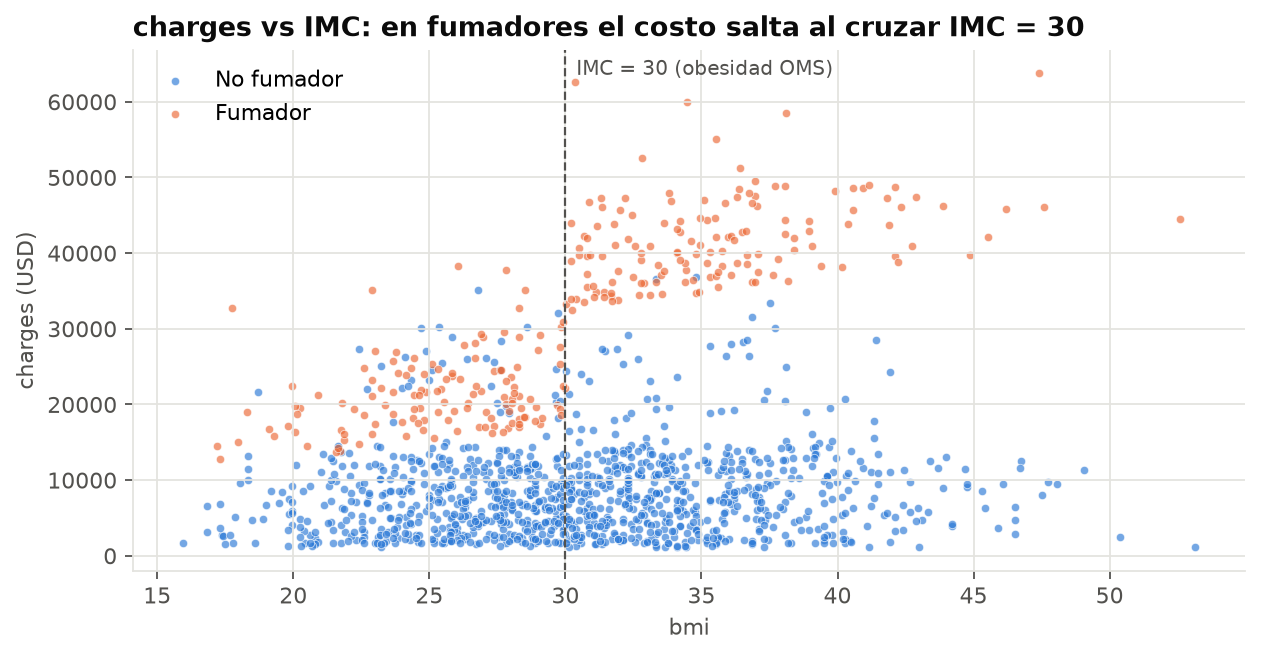

**05_boxplots_categoricas**

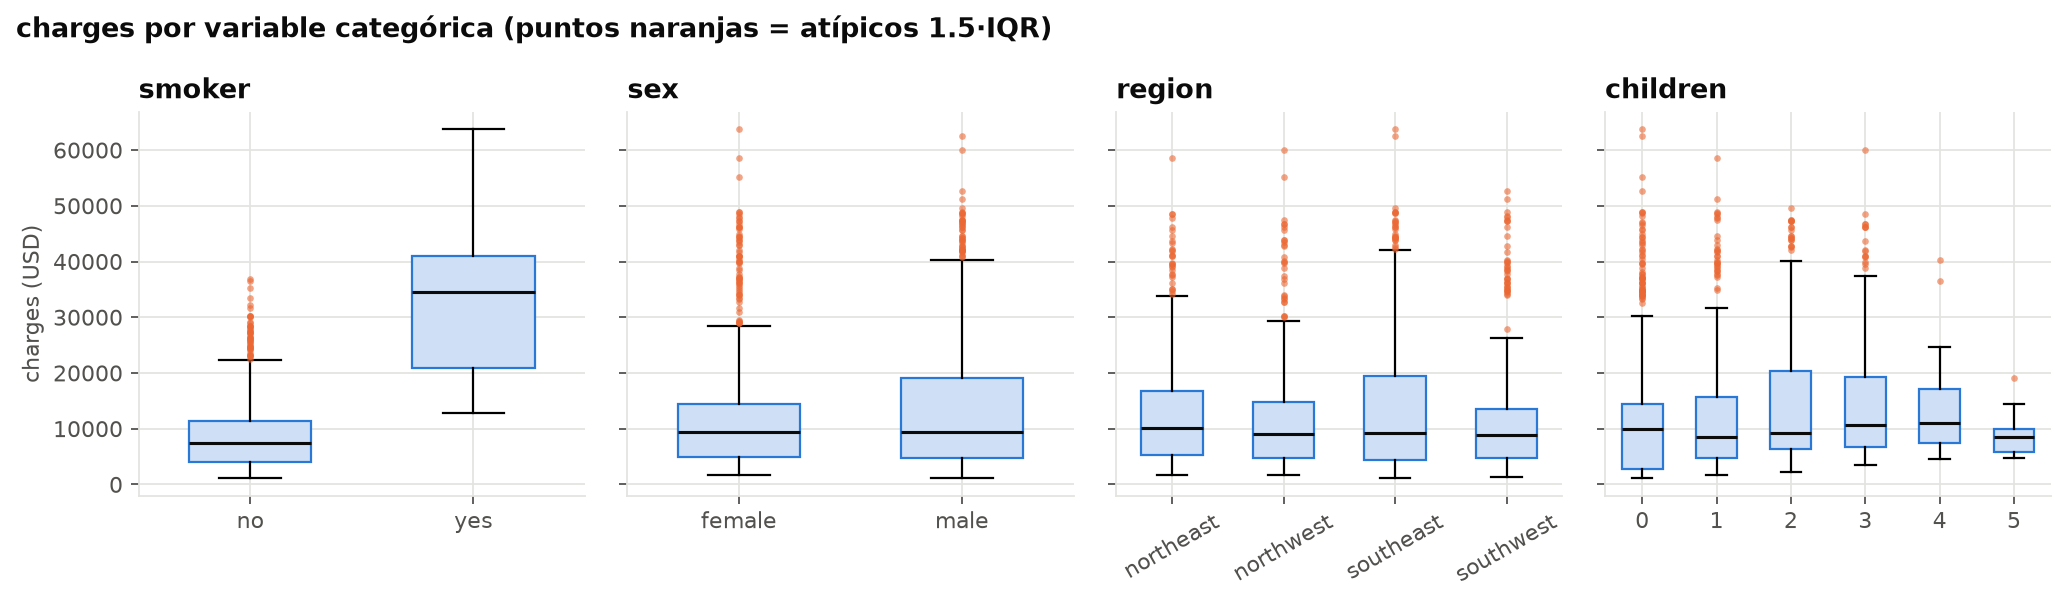

**06_correlacion**

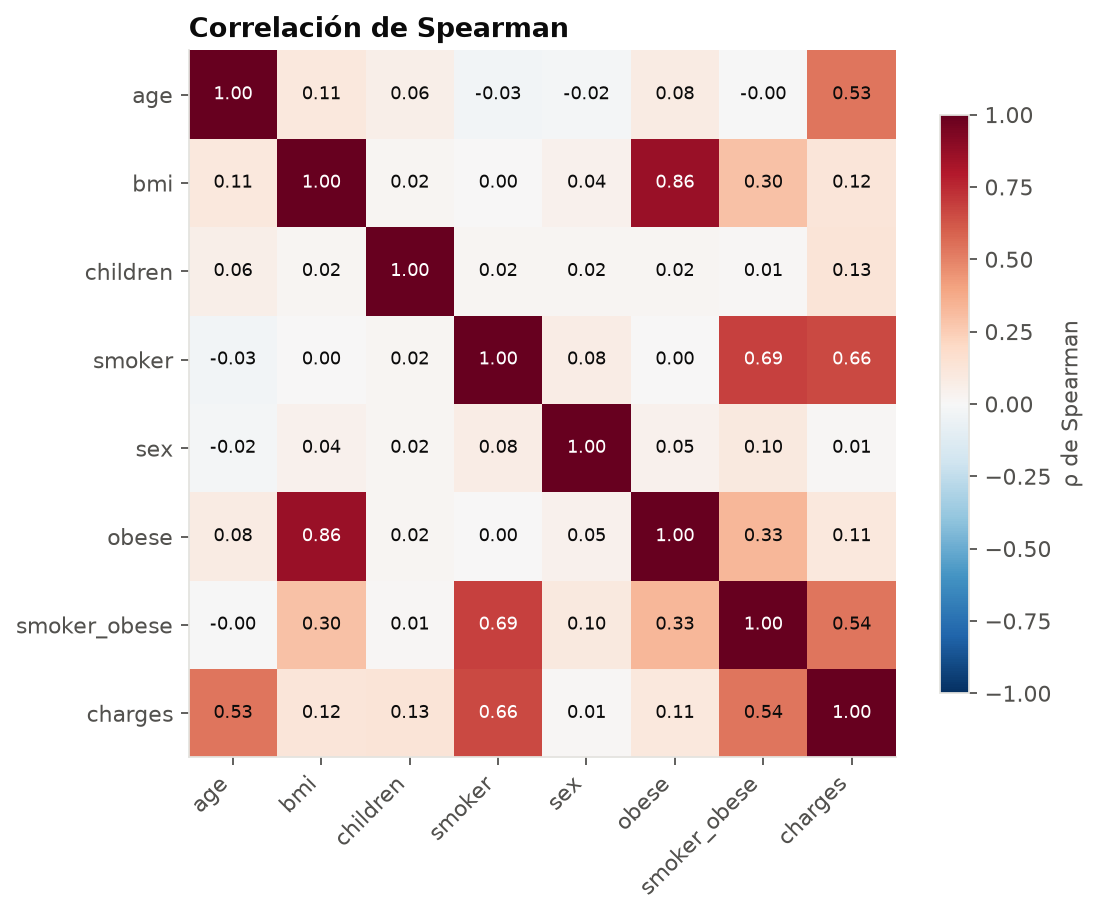

**07_atipicos_bmi**

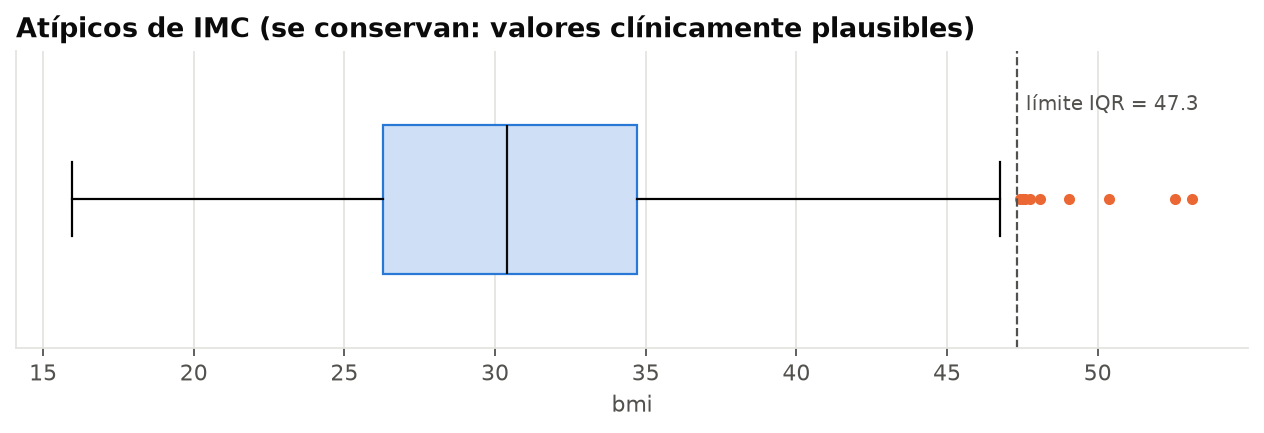

In [7]:
subprocess.run([sys.executable, "fuentes/eda.py"], check=True, capture_output=True)
resumen_eda = json.loads(Path("evidencias/eda/resumen_eda.json").read_text())
for f in sorted(Path("evidencias/eda").glob("*.png")):
    display(Markdown(f"**{f.stem}**"))
    display(Image(filename=str(f), width=780))

In [8]:
print(json.dumps(resumen_eda, indent=2, ensure_ascii=False))

{
  "charges_media_por_fumador": {
    "no": 8440.66,
    "yes": 32050.23
  },
  "charges_mediana_por_fumador": {
    "no": 7345.73,
    "yes": 34456.35
  },
  "charges_media_fumador_x_obeso": {
    "smoker=no,obese=0": 7977.03,
    "smoker=no,obese=1": 8855.53,
    "smoker=yes,obese=0": 21363.22,
    "smoker=yes,obese=1": 41557.99
  },
  "asimetria_charges": 1.515,
  "asimetria_log_charges": -0.09,
  "spearman_con_charges": {
    "age": 0.534,
    "bmi": 0.12,
    "children": 0.132,
    "smoker": 0.664,
    "sex": 0.011,
    "obese": 0.107,
    "smoker_obese": 0.537
  },
  "pct_fumadores": 20.49
}


**Lectura de las gráficas**
- `charges` es asimétrica a la derecha; `log(1+charges)` es casi simétrica → se prueba como hiperparámetro en el modelo lineal.
- Edad vs costo muestra **tres bandas paralelas**: no fumadores, fumadores con IMC < 30 y fumadores con IMC ≥ 30. La edad sube el costo de forma casi lineal dentro de cada banda.
- En fumadores el costo **salta al cruzar IMC = 30**; en no fumadores el IMC casi no influye → interacción tabaquismo × obesidad (`smoker_obese`).
- Sexo, región e hijos tienen efecto débil. Los atípicos de `charges` (≈10 %) son casi todos fumadores: son reales, no errores, y se conservan.

## 5. Entrenamiento, ajuste y registro en MLflow
`fuentes/train.py` entrena Ridge, Random Forest y XGBoost con `GridSearchCV` (K-Fold k=5, refit por RMSE), registra cada combinación del grid como corrida hija, guarda métricas de prueba, gráficas y el modelo, ejecuta la comparación estadística y registra al campeón en el Model Registry.

In [9]:
proc = subprocess.run([sys.executable, "fuentes/train.py"], capture_output=True, text=True)
print(proc.stdout[-6000:])
if proc.returncode != 0:
    print(proc.stderr[-4000:])
    raise RuntimeError("train.py falló")


=== Ridge (lineal) ===
  mejores params: {'best_alpha': 1.0, 'best_degree': 1, 'transformacion_objetivo': 'identidad'}
  CV RMSE 4,715.0 ± 650.8 | test RMSE 3,436.8  MAE 2,136.9  R² 0.9181

=== Random Forest ===
  mejores params: {'best_max_depth': 6, 'best_max_features': 0.5, 'best_min_samples_leaf': 5, 'best_n_estimators': 400}
  CV RMSE 4,725.6 ± 667.6 | test RMSE 3,410.6  MAE 2,165.7  R² 0.9193

=== XGBoost ===
  mejores params: {'best_learning_rate': 0.03, 'best_max_depth': 2, 'best_min_child_weight': 5, 'best_n_estimators': 200, 'best_subsample': 0.8}
  CV RMSE 4,701.3 ± 657.0 | test RMSE 3,422.5  MAE 2,135.9  R² 0.9187

Ablación de variables derivadas:
             modelo  variables_derivadas  ...  cv_rmse_std  cv_r2_media
0  regresion_lineal                False  ...      702.983        0.722
1     random_forest                False  ...      732.044        0.834
2  regresion_lineal                 True  ...      722.726        0.842
3     random_forest                 True  .

## 6. Comparación de modelos

**Hiperparámetros seleccionados**

modelo,ridge,random_forest,xgboost
best_best_alpha,1.0000,NaN,NaN
best_best_degree,1.0000,NaN,NaN
best_transformacion_objetivo,identidad,NaN,NaN
best_best_max_depth,NaN,6.0000,2.0000
best_best_max_features,NaN,0.5000,NaN
best_best_min_samples_leaf,NaN,5.0000,NaN
best_best_n_estimators,NaN,400.0000,200.0000
best_best_learning_rate,NaN,NaN,0.0300
best_best_min_child_weight,NaN,NaN,5.0000
best_best_subsample,NaN,NaN,0.8000


**Métricas (validación cruzada k=5 en entrenamiento y conjunto de prueba)**

,cv_rmse_media,cv_rmse_std,cv_mae_media,cv_r2_media,train_rmse,test_rmse,test_mae,test_r2,test_mape
modelo,,,,,,,,,
ridge,"4,714.9704",650.8290,"2,701.6314",0.8425,"4,700.2637","3,436.7634","2,136.9260",0.9181,26.4083
random_forest,"4,725.6442",667.6233,"2,759.7837",0.8416,"4,341.0835","3,410.5988","2,165.7074",0.9193,33.9528
xgboost,"4,701.2923",657.0297,"2,733.5373",0.8434,"4,505.8049","3,422.4895","2,135.9052",0.9187,31.5902


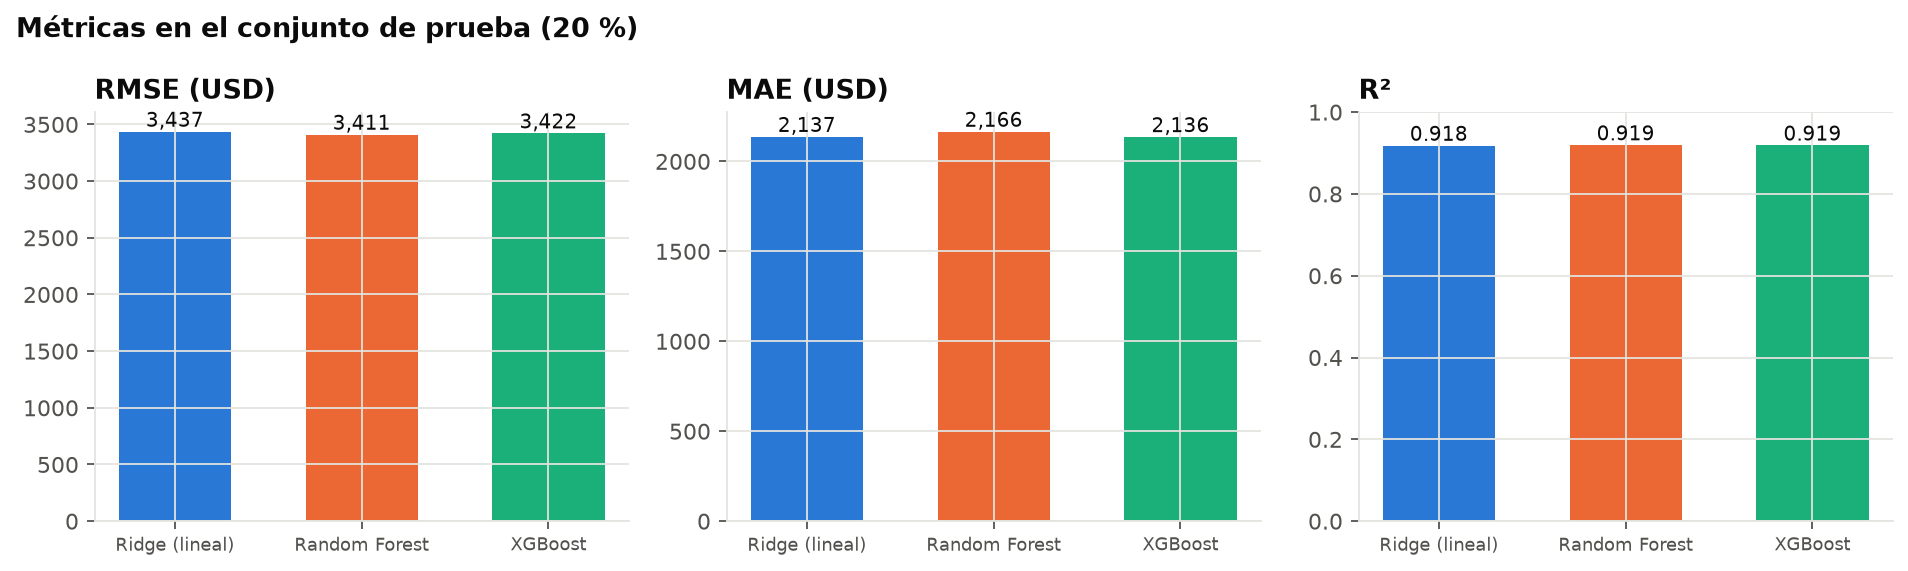

In [10]:
metr = pd.read_csv("resultados/metricas_modelos.csv", index_col="modelo")
cols = [c for c in metr.columns if c.startswith("best_")]
display(Markdown("**Hiperparámetros seleccionados**"))
display(metr[cols].T)
display(Markdown("**Métricas (validación cruzada k=5 en entrenamiento y conjunto de prueba)**"))
display(metr[["cv_rmse_media", "cv_rmse_std", "cv_mae_media", "cv_r2_media",
              "train_rmse", "test_rmse", "test_mae", "test_r2", "test_mape"]])
display(Image(filename="evidencias/modelos/comparacion_metricas_prueba.png", width=900))

**K-Fold repetido 5×5: media, desviación e IC 95 %**

media                        std                   ic95_inf                     ic95_sup                  
metrica              mae     r2       rmse      mae     r2     rmse        mae     r2       rmse        mae     r2       rmse
modelo                                                                                                                       
random_forest 2,754.6950 0.8420 4,750.5150 237.4840 0.0380 514.3960 2,656.6670 0.8270 4,538.1830 2,852.7240 0.8580 4,962.8470
ridge         2,707.8830 0.8440 4,722.3030 210.1230 0.0380 523.8840 2,621.1490 0.8280 4,506.0550 2,794.6180 0.8600 4,938.5520
xgboost       2,731.4300 0.8440 4,719.2030 226.7370 0.0370 511.7260 2,637.8380 0.8290 4,507.9730 2,825.0230 0.8590 4,930.4330

Friedman (RMSE): {'estadistico': 11.759999999999991, 'p_valor': 0.0027947852750368567}


,par,dif_media_rmse,t_nadeau_bengio,p_t,wilcoxon_W,p_wilcoxon,pliegues_gana_ridge,p_t_holm,p_wilcoxon_holm,significativo_5pct,pliegues_gana_random_forest
0,ridge vs random_forest,-28.2118,-0.8196,0.4205,87.0000,0.0422,16.0000,0.8410,0.0843,False,NaN
1,ridge vs xgboost,3.1001,0.1118,0.9119,149.0000,0.7310,11.0000,0.9119,0.7310,False,NaN
2,random_forest vs xgboost,31.3120,1.8990,0.0697,22.0000,0.0000,NaN,0.2090,0.0001,False,3.0000


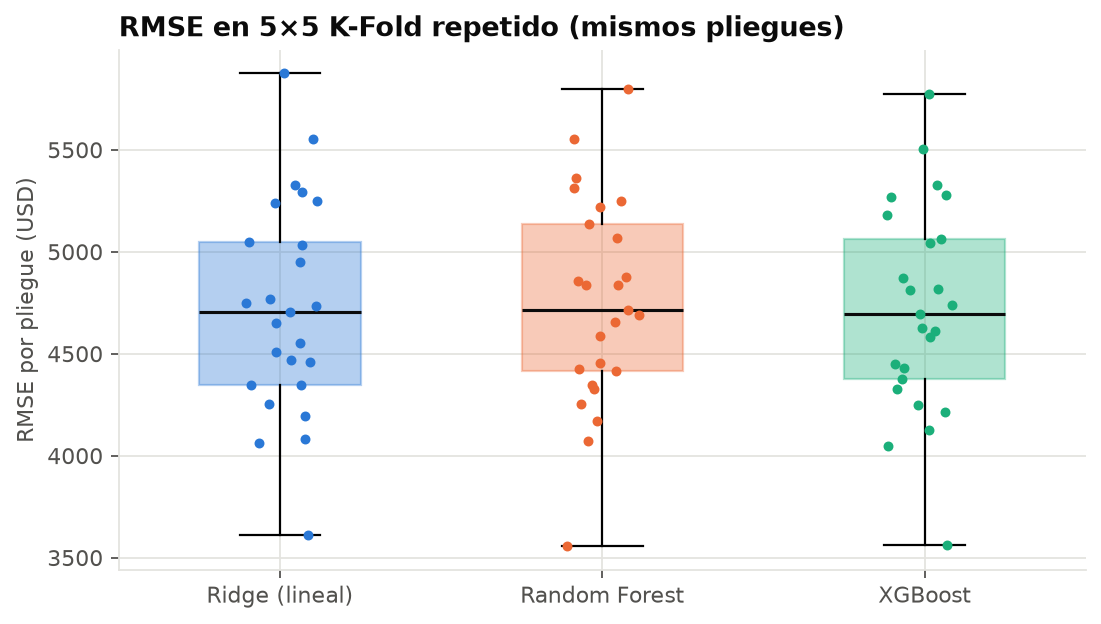

In [11]:
rcv = pd.read_csv("resultados/cv_repetido_resumen.csv")
display(Markdown("**K-Fold repetido 5×5: media, desviación e IC 95 %**"))
display(rcv.pivot(index="modelo", columns="metrica", values=["media", "std", "ic95_inf", "ic95_sup"]).round(3))
pruebas = json.loads(Path("resultados/pruebas_estadisticas.json").read_text())
if "friedman_rmse" in pruebas:
    print("Friedman (RMSE):", pruebas["friedman_rmse"])
display(pd.read_csv("resultados/pruebas_pareadas.csv"))
display(Image(filename="evidencias/modelos/comparacion_rmse_pliegues.png", width=700))

**Ablación: aporte de las variables derivadas del EDA**

,modelo,variables_derivadas,cv_rmse_media,cv_rmse_std,cv_r2_media
0,regresion_lineal,False,"6,297.1182",702.9834,0.7224
1,random_forest,False,"4,826.5855",732.0435,0.8343
2,regresion_lineal,True,"4,715.1787",722.7265,0.8425
3,random_forest,True,"4,811.0566",789.9775,0.8349


**ridge**

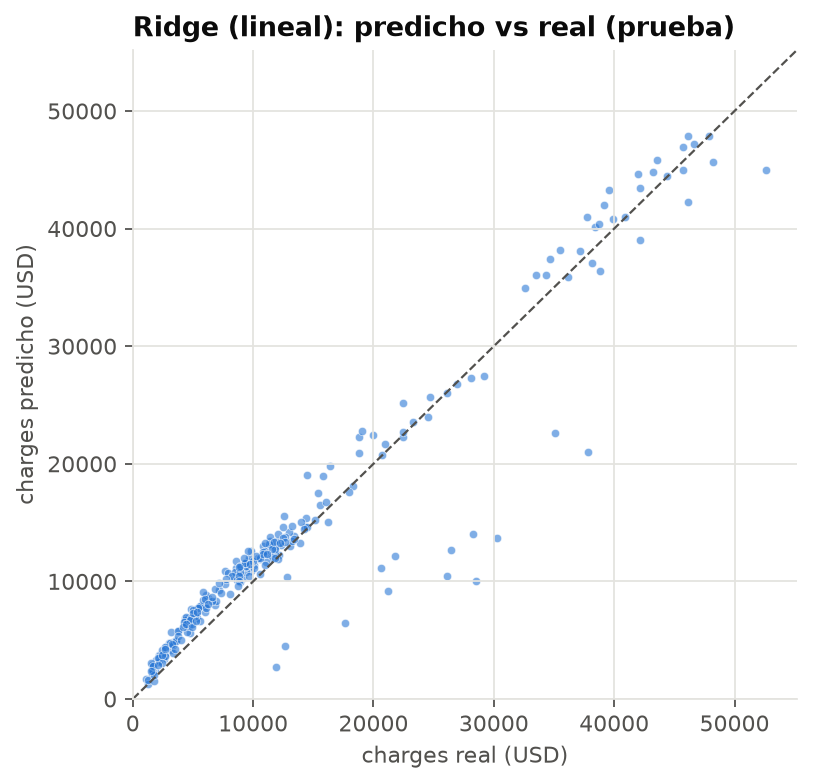

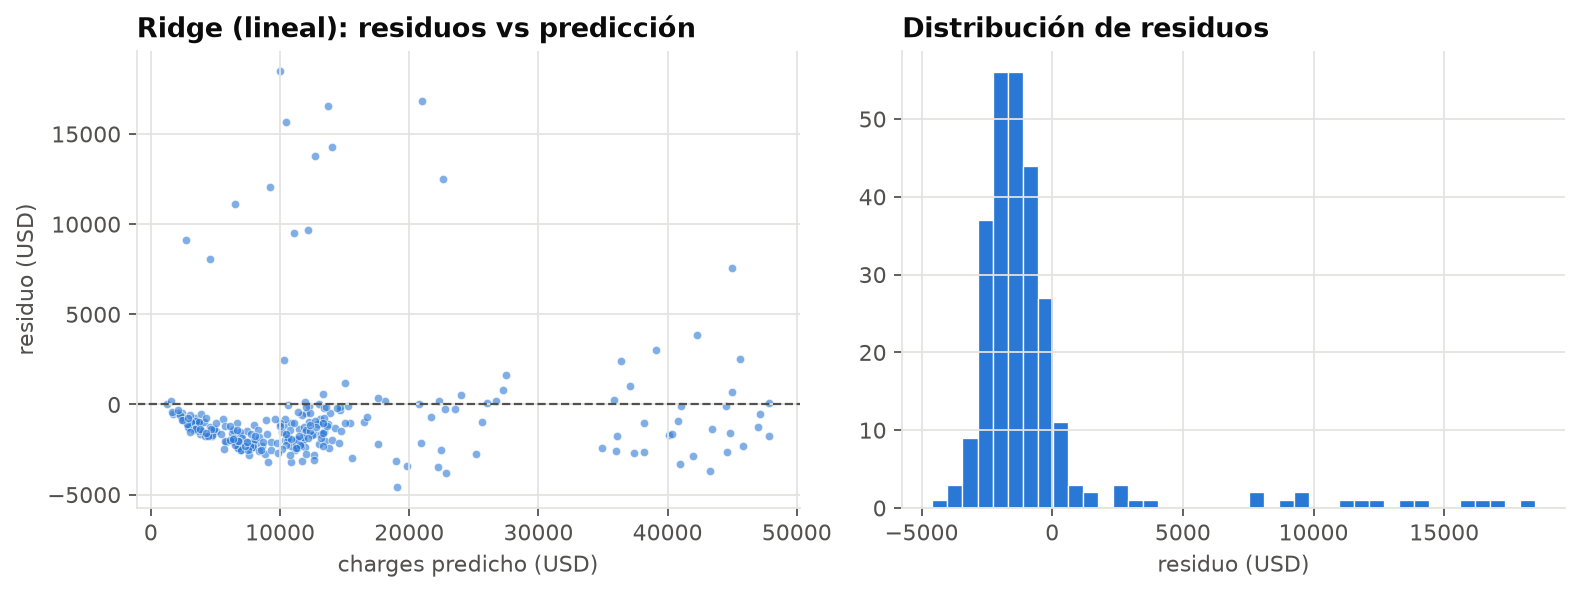

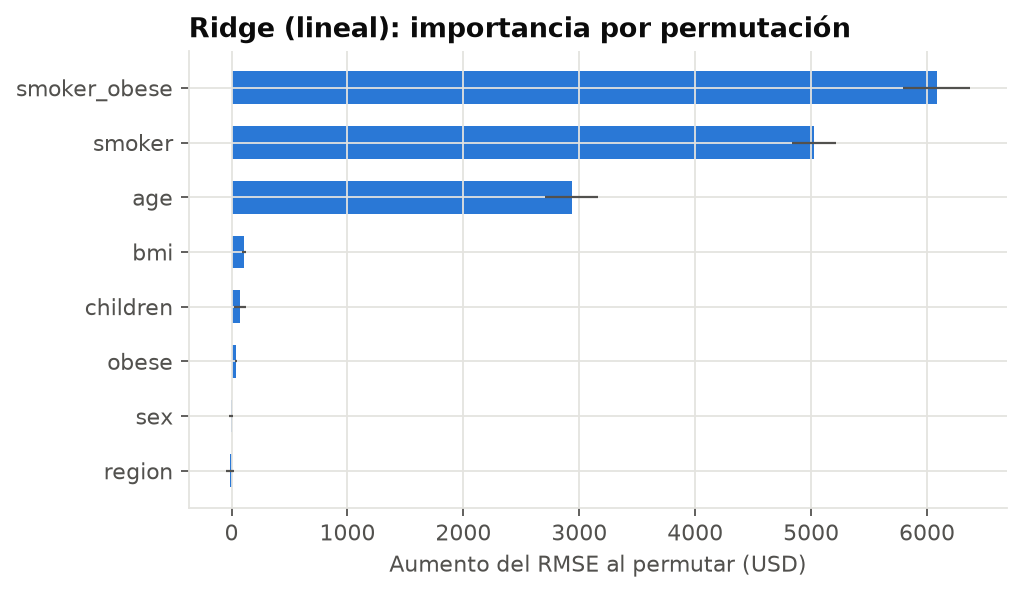

**random_forest**

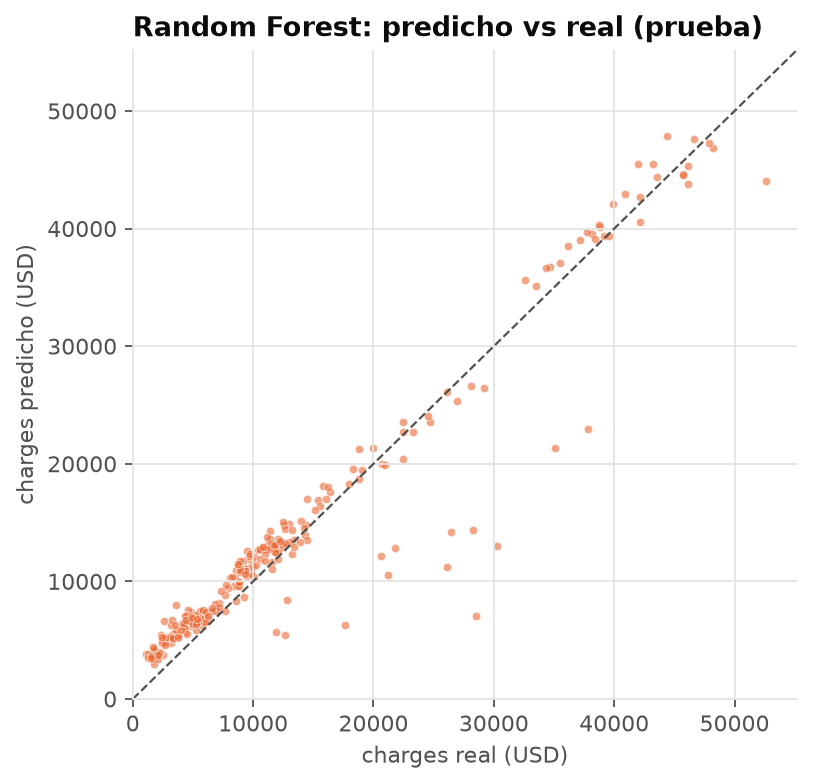

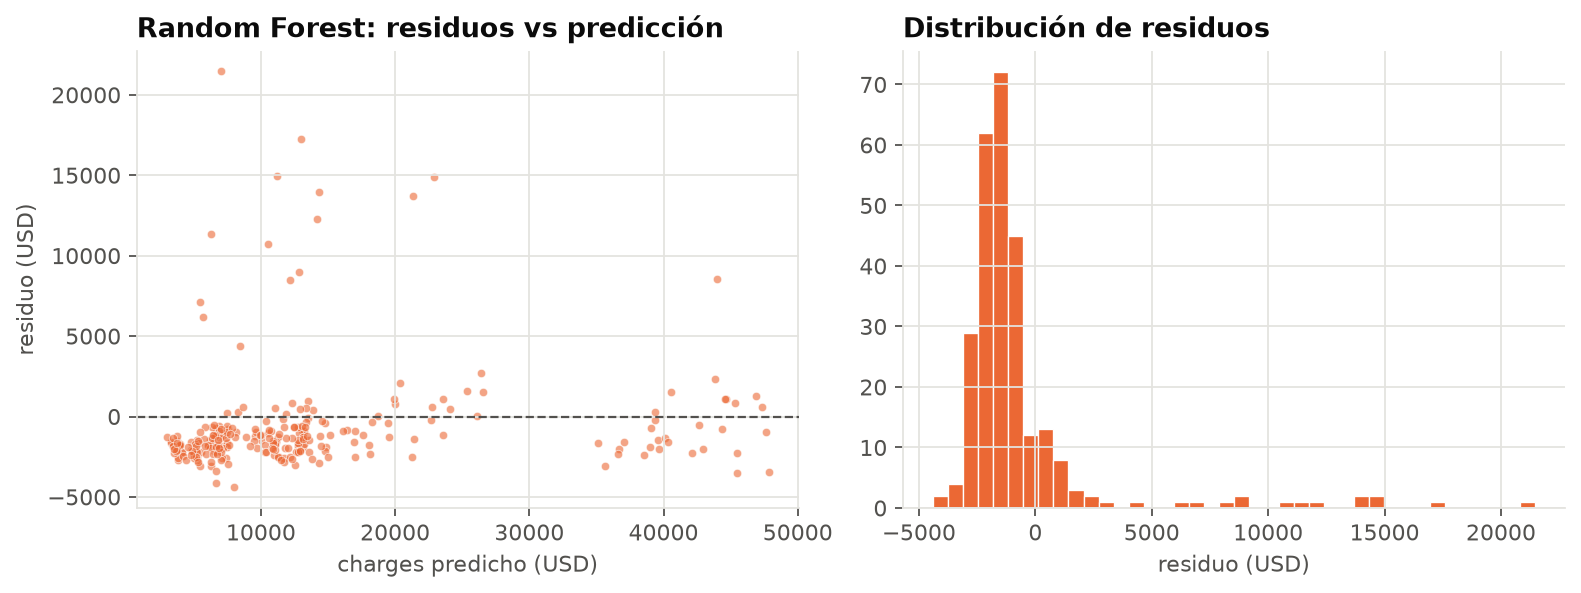

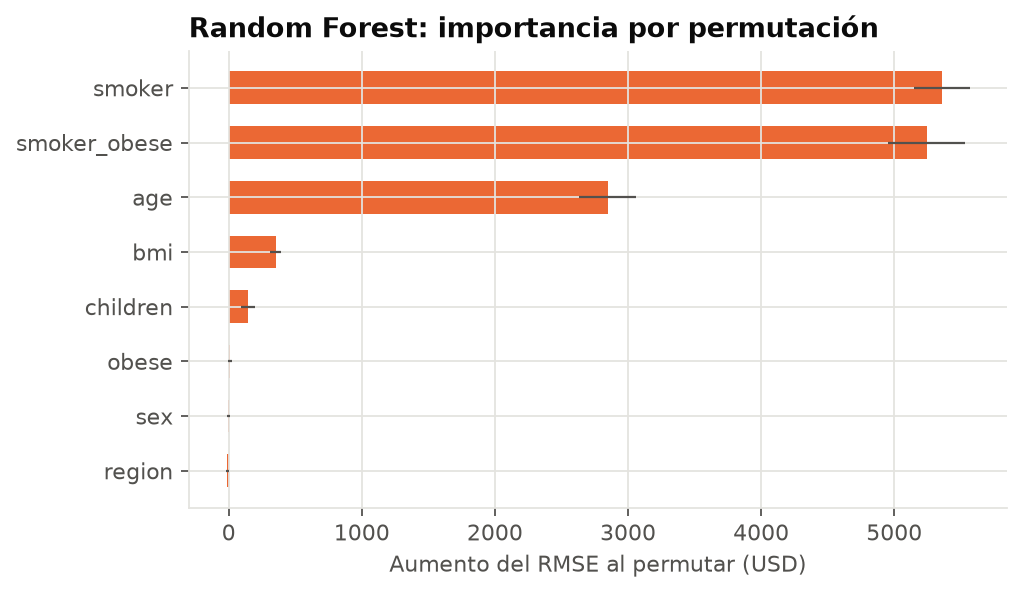

**xgboost**

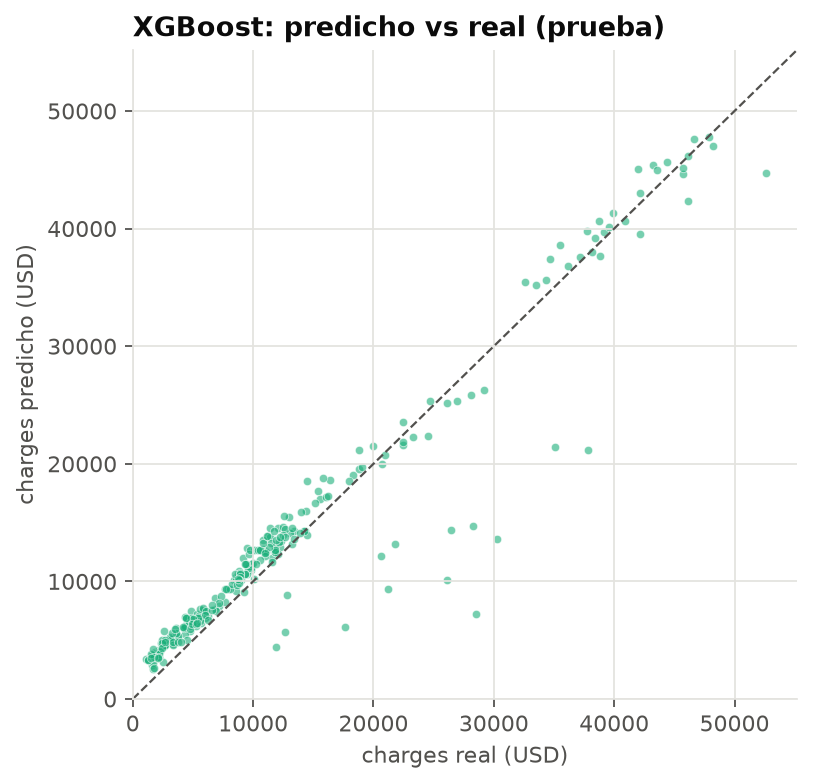

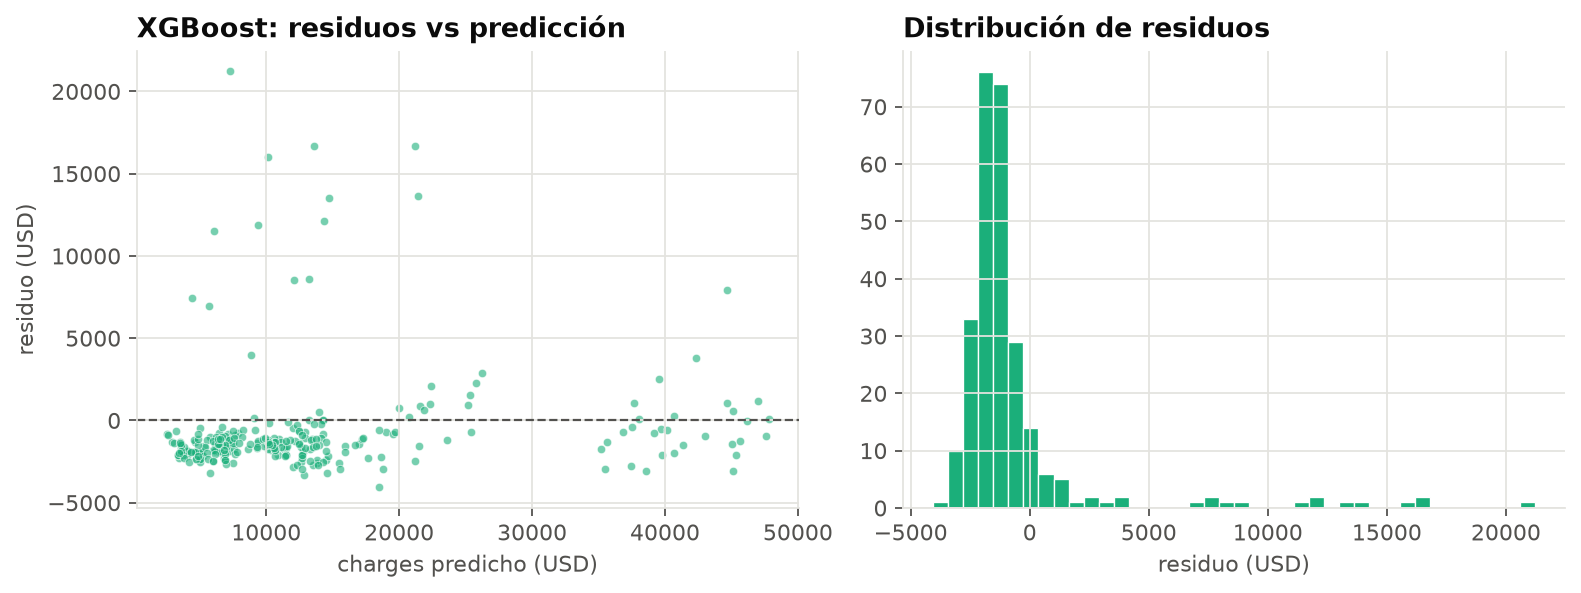

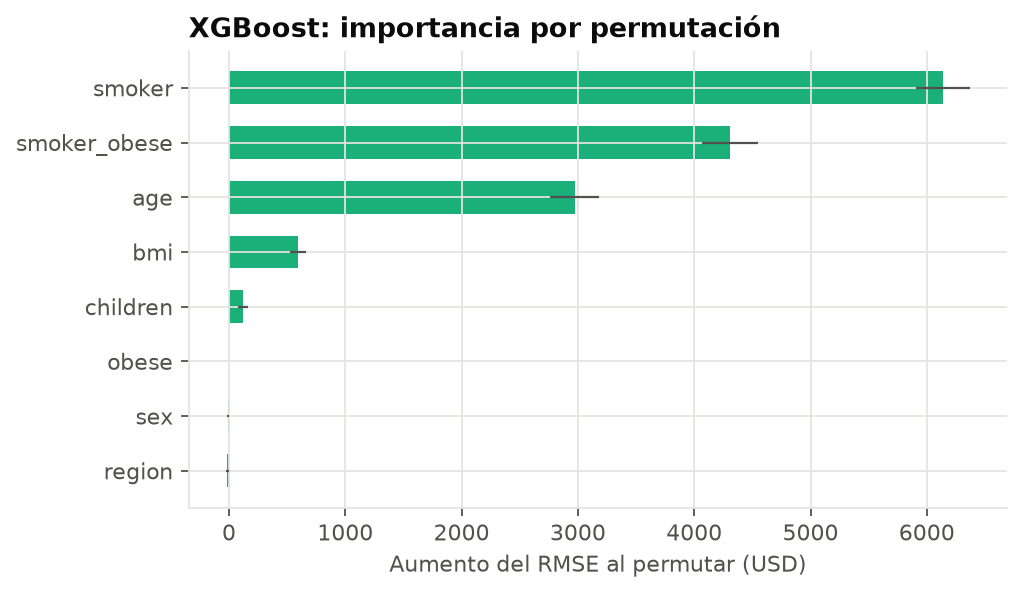

In [12]:
display(Markdown("**Ablación: aporte de las variables derivadas del EDA**"))
display(pd.read_csv("resultados/ablacion_variables.csv"))
for m in metr.index:
    display(Markdown(f"**{m}**"))
    for suf in ["pred_vs_real", "residuos", "importancia"]:
        display(Image(filename=f"evidencias/modelos/{m}_{suf}.png", width=620))

## 7. Evidencia de MLflow
Consulta directa al servidor de seguimiento: experimento, corridas padre/hijas, parámetros, métricas y versión registrada.

In [13]:
import mlflow
from mlflow.tracking import MlflowClient

mlflow.set_tracking_uri(f"sqlite:///{Path('mlflow.db').resolve()}")
exp = mlflow.get_experiment_by_name("seguros-costos-regresion")
print("Experimento:", exp.name, "| id:", exp.experiment_id)
runs = mlflow.search_runs([exp.experiment_id])
print("Corridas registradas:", len(runs))
principales = runs[runs["tags.tipo_corrida"].isin(["gridsearch", "comparacion", "ablacion"])]
cols = ["tags.mlflow.runName", "run_id", "status", "metrics.cv_rmse_media", "metrics.test_rmse",
        "metrics.test_mae", "metrics.test_r2"]
display(principales[[c for c in cols if c in principales.columns]])

Experimento: seguros-costos-regresion | id: 1
Corridas registradas: 109


,tags.mlflow.runName,run_id,status,metrics.cv_rmse_media,metrics.test_rmse,metrics.test_mae,metrics.test_r2
0,ablacion-variables-derivadas,5744b426cef44b28986ff2c9572e9cff,FINISHED,NaN,NaN,NaN,NaN
1,comparacion-estadistica,d0650d923084492babf2169ac654c60f,FINISHED,NaN,NaN,NaN,NaN
50,xgboost-gridsearch,b0cc18bd9fe34bb58b19236e0e046d0a,FINISHED,"4,701.2923","3,422.4895","2,135.9052",0.9187
87,random_forest-gridsearch,5d6f07688a324a50a59d003428880bed,FINISHED,"4,725.6442","3,410.5988","2,165.7074",0.9193
108,ridge-gridsearch,f738447d40214e9da7a0279513ebf3bd,FINISHED,"4,714.9704","3,436.7634","2,136.9260",0.9181


In [14]:
hijas = runs[runs["tags.tipo_corrida"] == "candidato"]
display(Markdown(f"**{len(hijas)} corridas hijas (una por combinación del grid)** — top 5 por modelo"))
display(hijas.sort_values("metrics.cv_rmse_media").groupby("tags.modelo").head(5)
        [["tags.mlflow.runName", "tags.modelo", "metrics.cv_rmse_media", "metrics.cv_rmse_std", "metrics.cv_r2_media"]])

**104 corridas hijas (una por combinación del grid)** — top 5 por modelo

,tags.mlflow.runName,tags.modelo,metrics.cv_rmse_media,metrics.cv_rmse_std,metrics.cv_r2_media
45,xgboost-cand-04,xgboost,"4,701.2923",657.0297,0.8434
37,xgboost-cand-12,xgboost,"4,701.5864",676.0677,0.8431
41,xgboost-cand-08,xgboost,"4,702.3875",686.4434,0.8430
49,xgboost-cand-00,xgboost,"4,705.2043",657.0827,0.8432
44,xgboost-cand-05,xgboost,"4,708.7401",664.9028,0.8429
99,ridge-cand-08,ridge,"4,714.9704",650.8290,0.8425
103,ridge-cand-04,ridge,"4,715.0838",646.8861,0.8425
107,ridge-cand-00,ridge,"4,715.1684",646.4724,0.8425
65,random_forest-cand-21,random_forest,"4,725.6442",667.6233,0.8416
66,random_forest-cand-20,random_forest,"4,731.7847",672.8253,0.8410


In [15]:
client = MlflowClient()
mv = client.get_model_version_by_alias("seguros-costos-regresor", "champion")
print(f"Modelo registrado: {mv.name} v{mv.version} | alias: champion | run: {mv.run_id}")
print("Descripción:", mv.description)
modelo = mlflow.pyfunc.load_model("models:/seguros-costos-regresor@champion")
ejemplo = limp.drop(columns="charges").sample(5, random_state=7)
salida = ejemplo.assign(charges_real=limp.loc[ejemplo.index, "charges"],
                        charges_predicho=modelo.predict(ejemplo))
display(salida)

Modelo registrado: seguros-costos-regresor v1 | alias: champion | run: b0cc18bd9fe34bb58b19236e0e046d0a
Descripción: XGBoost | test RMSE 3,422.5 | test R² 0.9187


,age,sex,bmi,children,smoker,region,obese,smoker_obese,charges_real,charges_predicho
13,56,female,39.8200,0,no,southeast,1,0,"11,090.7178","12,893.6201"
1051,49,male,29.8300,1,no,northeast,0,0,"9,288.0267","10,626.1367"
172,18,male,15.9600,0,no,northeast,0,0,"1,694.7964","2,522.1274"
395,46,male,19.8550,0,no,northwest,0,0,"7,526.7064","8,525.6230"
933,32,male,37.1800,2,no,southeast,1,0,"4,673.3922","7,055.0562"


## 8. Conclusiones

1. **Datos.** El dataset original solo tenía un duplicado exacto (1 338 → 1 337 filas) y ningún nulo ni valor fuera de rango; las reglas de limpieza se validaron además con datos sucios sintéticos y 6 pruebas unitarias. Los ~10 % de atípicos de `charges` son casi todos fumadores (97.8 %): son reales y se conservaron.
2. **Ingeniería de variables.** El EDA mostró tres bandas de costo (no fumador / fumador con IMC < 30 / fumador con IMC ≥ 30). La variable `smoker_obese` redujo el RMSE de la regresión lineal de 6 297 a 4 715 USD (−25 %), mientras que Random Forest casi no cambió (4 827 → 4 811) porque los árboles aprenden esa interacción por sí mismos.
3. **Ajuste.** En Ridge, la transformación log del objetivo empeoró el RMSE (mejor 4 961 vs 4 715 USD): el efecto del tabaquismo es aditivo en dólares, no multiplicativo. En los ensambles ganaron configuraciones conservadoras (XGBoost: profundidad 2, learning_rate 0.03, 200 árboles; RF: profundidad 6, hojas ≥ 5).
4. **Comparación.** Los tres modelos quedan prácticamente empatados: R² de prueba 0.918–0.919 y RMSE en K-Fold repetido 5×5 de 4 719 (XGBoost), 4 722 (Ridge) y 4 751 USD (RF). Friedman detecta diferencias de ranking (p = 0.003), pero ningún par es significativo con la t corregida de Nadeau-Bengio + Holm; la única diferencia consistente (RF peor que XGBoost en 22 de 25 pliegues, Wilcoxon-Holm p < 0.001) es de apenas 31 USD (< 1 % del RMSE).
5. **Decisión.** La regla automática registró a XGBoost como `champion` en el Model Registry; como Ridge es estadísticamente equivalente, más simple, interpretable y barato de servir, se recomienda evaluarlo como alternativa de producción (ver reflexión de deuda técnica en el reporte).
6. **Trazabilidad.** Cada corrida guarda commit de Git, versión y SHA-256 del dataset, semilla, versiones de librerías, el dataset de entrenamiento/prueba (`log_input`), métricas, artefactos y el modelo serializado con skops.